In [1]:
# Import libraries and locate the project

from pathlib import Path
import yaml
import wave
import numpy as np
import torch
import matplotlib.pyplot as plt

# Find the project folder
project = Path.cwd()

if project.name == "notebooks":
    project = project.parent

print("Project folder:", project)

Project folder: /Users/kanika/Desktop/Real-Time-Multi-Speaker-Meeting-Intelligence


In [2]:
# Load project configuration

config_path = project / "configs/ami_sample.yaml"

with open(config_path, "r") as file:
    config = yaml.safe_load(file)

print("Project:", config["project"]["name"])
print("Speaker model:", config["pipeline"]["diarization"]["backend"])
print("Speech model:", config["pipeline"]["asr"]["backend"])
print("Evaluation metrics:", config["evaluation"]["metrics"])
print("Output folder:", config["evaluation"]["output_dir"])

Project: real-time-multi-speaker-meeting-intelligence
Speaker model: pyannote
Speech model: placeholder
Evaluation metrics: ['der', 'wer', 'action_item_f1', 'latency_p95']
Output folder: outputs


In [3]:
# Locate AMI meeting audio

audio_file = project / (
    "data/raw/amicorpus/ES2002a/audio/"
    "ES2002a.Mix-Headset.wav"
)

if audio_file.exists():
    print("AMI meeting audio found!")
    print("File:", audio_file.name)
else:
    raise FileNotFoundError(f"Audio file not found: {audio_file}")

AMI meeting audio found!
File: ES2002a.Mix-Headset.wav


In [4]:
# Read audio information

with wave.open(str(audio_file), "rb") as audio:
    sample_rate = audio.getframerate()
    channels = audio.getnchannels()
    total_frames = audio.getnframes()
    sample_width = audio.getsampwidth()

duration = total_frames / sample_rate

print("Sample rate:", sample_rate, "Hz")
print("Channels:", channels)
print("Duration:", round(duration, 2), "seconds")
print("Duration:", round(duration / 60, 2), "minutes")
print("Sample width:", sample_width, "bytes")

Sample rate: 16000 Hz
Channels: 1
Duration: 1272.64 seconds
Duration: 21.21 minutes
Sample width: 2 bytes


In [ ]:
# play meeting audio

from IPython.display import Audio, display

# Play the complete meeting
display(Audio(filename=str(audio_file)))

In [6]:
# Read the first 10 seconds of the recording

with wave.open(str(audio_file), "rb") as audio:
    raw_audio = audio.readframes(sample_rate * 10)

# Convert 16-bit PCM audio into floating-point values
sound = np.frombuffer(raw_audio, dtype=np.int16)
sound = sound.astype(np.float32) / 32768.0

print("Samples loaded:", len(sound))
print("Duration:", len(sound) / sample_rate, "seconds")

# Listen to the sample
display(Audio(sound, rate=sample_rate))

Samples loaded: 160000
Duration: 10.0 seconds


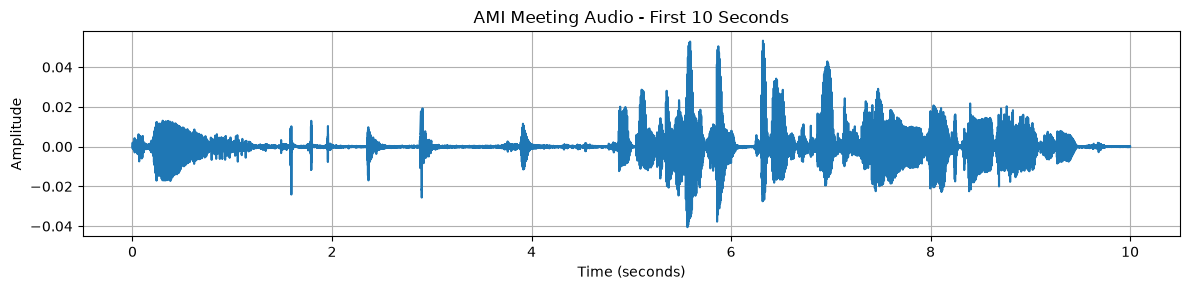

In [7]:
# Visualize the audio waveform

time = np.arange(len(sound)) / sample_rate

plt.figure(figsize=(12, 3))
plt.plot(time, sound)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("AMI Meeting Audio - First 10 Seconds")
plt.grid(True)
plt.tight_layout()
plt.show()

Looking at your graph:
- 0–1 seconds: Some sound is present.
- 1–4.8 seconds: Mostly quieter audio, with a few sharp spikes.
- 5–9.5 seconds: Much stronger and more continuous sound.
- 9.5–10 seconds: The sound becomes quiet again.
The larger waves could represent louder speech or other sounds. We cannot identify speakers or individual words from this graph alone.

In [8]:
# Verify the deep learning environment

from importlib.metadata import version
from pyannote.audio import Pipeline

print("PyTorch version:", torch.__version__)
print("pyannote.audio version:", version("pyannote.audio"))
print("Apple GPU available:", torch.backends.mps.is_available())

print("Environment verification successful!")

PyTorch version: 2.14.1
pyannote.audio version: 4.0.7
Apple GPU available: True
Environment verification successful!


In [9]:
# Convert audio values into a PyTorch tensor

waveform = torch.from_numpy(sound).unsqueeze(0)

print("Waveform shape:", waveform.shape)
print("Waveform data type:", waveform.dtype)

Waveform shape: torch.Size([1, 160000])
Waveform data type: torch.float32


In [10]:
# Prepare pyannote input

# Prepare the audio input for speaker diarization
audio_input = {
    "waveform": waveform,
    "sample_rate": sample_rate
}

print("Audio ready for speaker diarization!")
print("Duration:", waveform.shape[1] / sample_rate, "seconds")

Audio ready for speaker diarization!
Duration: 10.0 seconds


In [11]:
from getpass import getpass

hf_token = getpass("Enter your Hugging Face token: ")

print("Hugging Face token loaded successfully!")

Enter your Hugging Face token:  ········


Hugging Face token loaded successfully!


In [12]:
# Load the pretrained speaker diarization model


pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization-community-1",
    token=hf_token
)

print("Speaker diarization model loaded successfully!")

Speaker diarization model loaded successfully!


In [13]:
# Run speaker diarization

# Identify speakers in the first 10 seconds
output = pipeline(audio_input)

print("Speaker diarization completed!")

/Users/kanika/Desktop/Real-Time-Multi-Speaker-Meeting-Intelligence/.venv/lib/python3.13/site-packages/pyannote/audio/models/blocks/pooling.py:103: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1913.)
  std = sequences.std(dim=-1, correction=1)


Speaker diarization completed!


In [14]:
# Display who spoke and when

for turn, speaker in output.speaker_diarization:
    print(
        f"{speaker}: "
        f"{turn.start:.2f}s to {turn.end:.2f}s"
    )

SPEAKER_00: 0.03s to 0.87s
SPEAKER_00: 4.77s to 9.46s
SPEAKER_01: 7.35s to 7.83s
SPEAKER_01: 8.43s to 9.11s


In [15]:
# Count the detected speakers

speaker_ids = {
    speaker
    for turn, speaker in output.speaker_diarization
}

print("Number of speakers detected:", len(speaker_ids))
print("Speaker IDs:", sorted(speaker_ids))

Number of speakers detected: 2
Speaker IDs: ['SPEAKER_00', 'SPEAKER_01']


In [16]:
# Calculate how long each speaker talked

speaker_duration = {}

for turn, speaker in output.speaker_diarization:
    duration = turn.end - turn.start

    if speaker not in speaker_duration:
        speaker_duration[speaker] = 0

    speaker_duration[speaker] += duration

# Display the results
for speaker, duration in sorted(speaker_duration.items()):
    print(f"{speaker}: {duration:.2f} seconds")

SPEAKER_00: 5.54 seconds
SPEAKER_01: 1.15 seconds


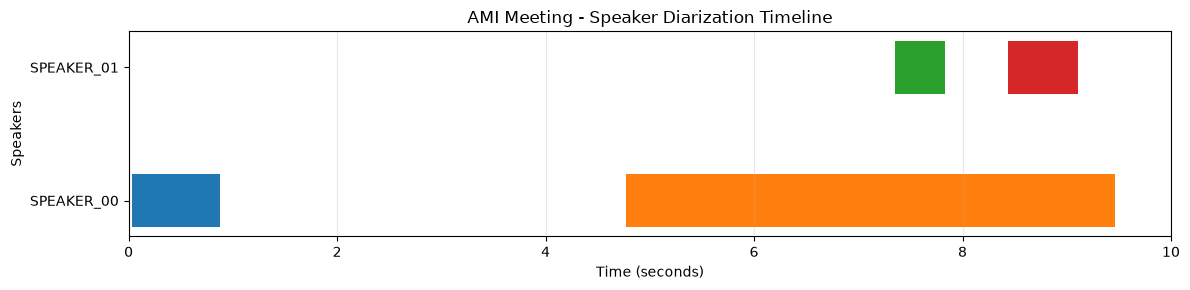

In [17]:
# Visualize speaker diarization results

import matplotlib.pyplot as plt

speaker_ids = sorted({
    speaker for turn, speaker in output.speaker_diarization
})

speaker_positions = {
    speaker: i for i, speaker in enumerate(speaker_ids)
}

plt.figure(figsize=(12, 3))

for turn, speaker in output.speaker_diarization:
    plt.barh(
        speaker_positions[speaker],
        turn.end - turn.start,
        left=turn.start,
        height=0.4
    )

plt.yticks(
    range(len(speaker_ids)),
    speaker_ids
)

plt.xlabel("Time (seconds)")
plt.ylabel("Speakers")
plt.title("AMI Meeting - Speaker Diarization Timeline")
plt.xlim(0, 10)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Look for AMI speaker annotation files
annotation_files = []

for extension in ("*.rttm", "*.xml"):
    annotation_files.extend(
        project.rglob(extension)
    )

print("Annotation files found:", len(annotation_files))

for file in annotation_files[:20]:
    print(file.relative_to(project))

Annotation files found: 4
data/raw/amicorpus/ES2002a/annotations/ES2002a.rttm
.venv/lib/python3.13/site-packages/pyannote/audio/sample/sample.rttm
.venv/lib/python3.13/site-packages/setuptools/launcher manifest.xml
.venv/lib/python3.13/site-packages/tornado/test/static/sample.xml


In [19]:
# Load AMI ground-truth speaker annotations

from pyannote.database.util import load_rttm

rttm_file = project / (
    "data/raw/amicorpus/ES2002a/"
    "annotations/ES2002a.rttm"
)

# Read the reference speaker timestamps
references = load_rttm(rttm_file)

print("RTTM file found:", rttm_file.exists())
print("Recording IDs:", list(references.keys()))

RTTM file found: True
Recording IDs: ['ES2002a']


In [20]:
# Calculate Diarization Error Rate (DER)

from pyannote.metrics.diarization import DiarizationErrorRate
from pyannote.core import Segment, Timeline

# Ground-truth speaker annotations
reference = references["ES2002a"]

# Predicted speaker annotations
hypothesis = output.speaker_diarization

# Evaluate only the first 10 seconds
evaluation_region = Timeline([
    Segment(0, 10)
])

# Create DER metric
metric = DiarizationErrorRate(collar=0.0, skip_overlap=False)

# Calculate DER
der = metric(
    reference,
    hypothesis,
    uem=evaluation_region
)

print("Meeting: ES2002a")
print("Evaluated duration: 10 seconds")
print(f"Diarization Error Rate (DER): {der * 100:.2f}%")

Meeting: ES2002a
Evaluated duration: 10 seconds
Diarization Error Rate (DER): 100.00%


In [21]:
# Inspect the actual speaker annotations

reference = references["ES2002a"]

print("Ground-truth speakers in the first 10 seconds:")
print("-" * 50)

for turn, track, speaker in reference.itertracks(yield_label=True):
    if turn.start < 10 and turn.end > 0:
        print(
            f"{speaker}: "
            f"{turn.start:.2f}s to {turn.end:.2f}s"
        )

print("-" * 50)

print("Model predictions:")
for turn, speaker in output.speaker_diarization:
    print(
        f"{speaker}: "
        f"{turn.start:.2f}s to {turn.end:.2f}s"
    )

Ground-truth speakers in the first 10 seconds:
--------------------------------------------------
--------------------------------------------------
Model predictions:
SPEAKER_00: 0.03s to 0.87s
SPEAKER_00: 4.77s to 9.46s
SPEAKER_01: 7.35s to 7.83s
SPEAKER_01: 8.43s to 9.11s


In [22]:
# Check when the reference annotations begin


reference = references["ES2002a"]

segments = sorted(
    reference.itertracks(yield_label=True),
    key=lambda item: item[0].start
)

print("Total reference segments:", len(segments))

print("\nFirst 10 reference annotations:")

for turn, track, speaker in segments[:10]:
    print(
        f"{speaker}: "
        f"{turn.start:.2f}s to {turn.end:.2f}s"
    )

if segments:
    print("\nFirst annotated speech starts at:",
          round(segments[0][0].start, 2), "seconds")

Total reference segments: 236

First 10 reference annotations:
FEE005: 50.42s to 50.99s
FEE005: 53.56s to 53.96s
FEE005: 55.98s to 77.29s
MEE008: 67.21s to 67.45s
MEE008: 74.89s to 75.24s
MEE006: 77.44s to 80.87s
FEE005: 80.81s to 81.26s
MEE008: 82.08s to 84.46s
MEE007: 85.99s to 88.71s
MEE008: 86.07s to 86.50s

First annotated speech starts at: 50.42 seconds


In [23]:
# Listen to the audio at 50–60 seconds

from IPython.display import Audio, display
import wave
import numpy as np

# Listen from 50 to 60 seconds
start_time = 50
end_time = 60

with wave.open(str(audio_file), "rb") as f:
    f.setpos(start_time * sample_rate)
    raw_audio = f.readframes((end_time - start_time) * sample_rate)

audio_segment = np.frombuffer(
    raw_audio, dtype=np.int16
).astype(np.float32) / 32768.0

print("Playing audio from 50 to 60 seconds")
display(Audio(audio_segment, rate=sample_rate))

Playing audio from 50 to 60 seconds


In [24]:
# Run speaker diarization on 50–60 seconds

audio_input_50_60 = {
    "waveform": torch.from_numpy(audio_segment).unsqueeze(0),
    "sample_rate": sample_rate
}

# Run the pretrained speaker diarization model
output_50_60 = pipeline(audio_input_50_60)

print("Diarization completed!")

# Display speaker predictions
for turn, speaker in output_50_60.speaker_diarization:
    print(
        f"{speaker}: "
        f"{turn.start + 50:.2f}s to {turn.end + 50:.2f}s"
    )

Diarization completed!
SPEAKER_00: 50.03s to 51.08s
SPEAKER_00: 53.56s to 54.71s
SPEAKER_00: 55.92s to 59.97s


In [25]:
# Calculate DER for 50–60 seconds

from pyannote.core import Annotation, Segment, Timeline
from pyannote.metrics.diarization import DiarizationErrorRate

# Shift predictions to the original meeting timestamps
hypothesis_50_60 = Annotation(uri="ES2002a")

for turn, speaker in output_50_60.speaker_diarization:
    hypothesis_50_60[
        Segment(turn.start + 50, turn.end + 50)
    ] = speaker

# Evaluate only 50–60 seconds
evaluation_region = Timeline([Segment(50, 60)])

metric = DiarizationErrorRate(
    collar=0.0,
    skip_overlap=False
)

der = metric(
    reference,
    hypothesis_50_60,
    uem=evaluation_region
)

print("Meeting: ES2002a")
print("Evaluation interval: 50–60 seconds")
print(f"DER: {der * 100:.2f}%")

Meeting: ES2002a
Evaluation interval: 50–60 seconds
DER: 26.31%


In [26]:
# Show detailed diarization errors

details = metric(
    reference,
    hypothesis_50_60,
    uem=evaluation_region,
    detailed=True
)

print("DER error breakdown:")
for name, value in details.items():
    print(f"{name}: {value:.3f}")

DER error breakdown:
missed detection: 0.030
correct: 4.960
total: 4.990
confusion: 0.000
false alarm: 1.283
diarization error rate: 0.263


In [27]:
# Evaluate a longer section

import torch

print("PyTorch version:", torch.__version__)
print("Apple GPU available:", torch.backends.mps.is_available())

# Find the device used by the segmentation model
model_device = next(pipeline._segmentation.model.parameters()).device

print("Segmentation model device:", model_device)

PyTorch version: 2.14.1
Apple GPU available: True
Segmentation model device: cpu


In [28]:
# Run speaker diarization on a 60-second meeting segment

start_time = 50
end_time = 110

# Read the selected audio segment
with wave.open(str(audio_file), "rb") as f:
    f.setpos(int(start_time * sample_rate))
    raw_audio_60 = f.readframes(
        int((end_time - start_time) * sample_rate)
    )

# Convert audio into floating-point values
sound_60 = np.frombuffer(
    raw_audio_60, dtype=np.int16
).astype(np.float32) / 32768.0

# Convert to PyTorch tensor
waveform_60 = torch.from_numpy(sound_60).unsqueeze(0)

# Prepare model input
audio_input_60 = {
    "waveform": waveform_60,
    "sample_rate": sample_rate
}

print("Audio duration:", waveform_60.shape[1] / sample_rate, "seconds")

# Run pyannote
output_60 = pipeline(audio_input_60)

print("60-second diarization completed!")

# Display predicted speaker timestamps
for turn, speaker in output_60.speaker_diarization:
    print(
        f"{speaker}: "
        f"{turn.start + start_time:.2f}s to "
        f"{turn.end + start_time:.2f}s"
    )

Audio duration: 60.0 seconds
60-second diarization completed!
SPEAKER_02: 50.03s to 51.03s
SPEAKER_02: 53.56s to 54.11s
SPEAKER_02: 55.95s to 75.12s
SPEAKER_00: 67.23s to 67.43s
SPEAKER_00: 74.96s to 75.16s
SPEAKER_02: 75.16s to 77.37s
SPEAKER_01: 77.37s to 80.66s
SPEAKER_02: 80.78s to 81.25s
SPEAKER_00: 82.06s to 84.47s
SPEAKER_00: 85.94s to 88.66s
SPEAKER_02: 89.30s to 101.74s
SPEAKER_02: 104.89s to 106.19s
SPEAKER_02: 108.69s to 109.97s


In [30]:
# Evaluate the 60-second diarization results

from pyannote.core import Annotation, Segment, Timeline
from pyannote.metrics.diarization import DiarizationErrorRate

# Convert predictions to original meeting timestamps
hypothesis_60 = Annotation(uri="ES2002a")

for turn, speaker in output_60.speaker_diarization:
    hypothesis_60[
        Segment(turn.start + 50, turn.end + 50)
    ] = speaker

# Evaluate from 50 to 110 seconds
evaluation_region_60 = Timeline([
    Segment(50, 110)
])

metric_60 = DiarizationErrorRate(
    collar=0.0,
    skip_overlap=False
)

# Calculate detailed evaluation results
details_60 = metric_60(
    reference,
    hypothesis_60,
    uem=evaluation_region_60,
    detailed=True
)

print("Meeting: ES2002a")
print("Evaluation interval: 50–110 seconds")
print()

for name, value in details_60.items():
    print(f"{name}: {value:.3f}")

print()
print(f"DER: {details_60['diarization error rate'] * 100:.2f}%")

Meeting: ES2002a
Evaluation interval: 50–110 seconds

missed detection: 1.333
correct: 43.866
total: 47.470
confusion: 2.271
false alarm: 1.113
diarization error rate: 0.099

DER: 9.94%


In [31]:
# Check AMI ground-truth annotation coverage


import wave

with wave.open(str(audio_file), "rb") as f:
    audio_duration = f.getnframes() / f.getframerate()

reference = references["ES2002a"]
segments = list(reference.itertracks(yield_label=True))

first_speech = min(turn.start for turn, track, speaker in segments)
last_speech = max(turn.end for turn, track, speaker in segments)

reference_speakers = sorted({
    speaker for turn, track, speaker in segments
})

print("Meeting: ES2002a")
print("Audio duration:", round(audio_duration, 2), "seconds")
print("First annotated speech:", round(first_speech, 2), "seconds")
print("Last annotated speech:", round(last_speech, 2), "seconds")
print("Reference segments:", len(segments))
print("Reference speakers:", len(reference_speakers))
print("Speaker IDs:", reference_speakers)

print(
    "Annotations within audio:",
    0 <= first_speech <= last_speech <= audio_duration
)

Meeting: ES2002a
Audio duration: 1272.64 seconds
First annotated speech: 50.42 seconds
Last annotated speech: 1109.45 seconds
Reference segments: 236
Reference speakers: 4
Speaker IDs: ['FEE005', 'MEE006', 'MEE007', 'MEE008']
Annotations within audio: True


In [32]:
# Select the entire AMI meeting recording

evaluation_start = 0
evaluation_end = audio_duration

evaluation_duration = evaluation_end - evaluation_start

print("Meeting:", "ES2002a")
print("Start:", evaluation_start, "seconds")
print("End:", evaluation_end, "seconds")
print("Duration:", evaluation_duration, "seconds")
print("Duration in minutes:", round(evaluation_duration / 60, 2))

print(
    "Interval fits within audio:",
    0 <= evaluation_start < evaluation_end <= audio_duration
)

Meeting: ES2002a
Start: 0 seconds
End: 1272.64 seconds
Duration: 1272.64 seconds
Duration in minutes: 21.21
Interval fits within audio: True


In [33]:
# Load audio for longer diarization evaluation

import wave
import numpy as np
import torch

with wave.open(str(audio_file), "rb") as f:
    f.setpos(int(evaluation_start * sample_rate))
    raw_audio_long = f.readframes(
        int((evaluation_end - evaluation_start) * sample_rate)
    )

# Convert 16-bit audio into floating-point values
sound_long = np.frombuffer(
    raw_audio_long,
    dtype=np.int16
).astype(np.float32) / 32768.0

# Convert to PyTorch tensor
waveform_long = torch.from_numpy(sound_long).unsqueeze(0)

audio_input_long = {
    "waveform": waveform_long,
    "sample_rate": sample_rate
}

print("Audio loaded successfully!")
print("Sample rate:", sample_rate)
print("Waveform shape:", waveform_long.shape)
print("Duration:", waveform_long.shape[1] / sample_rate, "seconds")

Audio loaded successfully!
Sample rate: 16000
Waveform shape: torch.Size([1, 20362240])
Duration: 1272.64 seconds


In [34]:
# Run speaker diarization on the longer recording

import time

# Measure processing time
start = time.perf_counter()

# Run speaker diarization
output_long = pipeline(audio_input_long)

processing_time = time.perf_counter() - start

# Count detected speakers
long_segments = list(output_long.speaker_diarization)

detected_speakers = sorted({
    speaker for turn, speaker in long_segments
})

print("Long recording diarization completed!")
print("Audio duration:", evaluation_duration, "seconds")
print("Processing time:", round(processing_time, 2), "seconds")
print("Detected speakers:", len(detected_speakers))
print("Speaker IDs:", detected_speakers)
print("Speech segments:", len(long_segments))

Long recording diarization completed!
Audio duration: 1272.64 seconds
Processing time: 1273.41 seconds
Detected speakers: 4
Speaker IDs: ['SPEAKER_00', 'SPEAKER_01', 'SPEAKER_02', 'SPEAKER_03']
Speech segments: 354


In [35]:
# Evaluate diarization on the longer recording

from pyannote.core import Annotation, Segment, Timeline
from pyannote.metrics.diarization import DiarizationErrorRate

# Shift predictions to original meeting timestamps
hypothesis_long = Annotation(uri="ES2002a")

for turn, speaker in output_long.speaker_diarization:
    hypothesis_long[
        Segment(
            turn.start + evaluation_start,
            turn.end + evaluation_start
        )
    ] = speaker

# Define evaluation interval
evaluation_region_long = Timeline([
    Segment(evaluation_start, evaluation_end)
])

# Calculate DER
metric_long = DiarizationErrorRate(
    collar=0.0,
    skip_overlap=False
)

details_long = metric_long(
    reference,
    hypothesis_long,
    uem=evaluation_region_long,
    detailed=True
)

print("Meeting: ES2002a")
print("Evaluation duration:", evaluation_duration, "seconds")
print()

for name, value in details_long.items():
    print(f"{name}: {value:.3f}")

print()
print(f"DER: {details_long['diarization error rate'] * 100:.2f}%")

Meeting: ES2002a
Evaluation duration: 1272.64 seconds

missed detection: 59.007
correct: 815.060
total: 890.470
confusion: 16.403
false alarm: 109.586
diarization error rate: 0.208

DER: 20.78%
